In [ ]:
!git clone https://github.com/Wisteria717/Chords_Dataset.git

Cloning into 'Chords_Dataset'...
remote: Enumerating objects: 45, done.
remote: Counting objects: 100% (45/45), done.
remote: Compressing objects: 100% (39/39), done.
remote: Total 45 (delta 6), reused 38 (delta 3), pack-reused 0 (from 0)
Receiving objects: 100% (45/45), 7.10 KiB | 1.78 MiB/s, done.
Resolving deltas: 100% (6/6), done.


In [ ]:
!rm -rf /content/Chords_Dataset
!apt-get install -y git-lfs
!git lfs install
!git clone https://github.com/Wisteria717/Chords_Dataset.git
!ls -lh /content/Chords_Dataset/WavFiles

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following NEW packages will be installed:
  git-lfs
0 upgraded, 1 newly installed, 0 to remove and 33 not upgraded.
Need to get 3,908 kB of archives.
After this operation, 11.7 MB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble-updates/universe amd64 git-lfs amd64 3.4.1-1ubuntu0.4 [3,908 kB]
Fetched 3,908 kB in 2s (1,623 kB/s)
Selecting previously unselected package git-lfs.
(Reading database ... 127324 files and directories currently installed.)
Preparing to unpack .../git-lfs_3.4.1-1ubuntu0.4_amd64.deb ...
Unpacking git-lfs (3.4.1-1ubuntu0.4) ...
Setting up git-lfs (3.4.1-1ubuntu0.4) ...
Processing triggers for man-db (2.12.0-4build2) ...
Git LFS initialized.
Cloning into 'Chords_Dataset'...
remote: Enumerating objects: 45, done.
remote: Counting objects: 100% (45/45), done.
remote: Compressing objects: 100% (39/39), done.
remote: Total 45 (delta 6)

In [ ]:
%cd /content/Chords_Dataset
!git lfs pull
%cd /content
!ls -lh /content/Chords_Dataset/WavFiles

/content/Chords_Dataset
/content
total 195M
-rw-r--r-- 1 root root 8.2M Oct 30 07:52 'ChordFinderDataset - MajorC2-B3_Organ.wav'
-rw-r--r-- 1 root root 8.1M Oct 30 07:52 'ChordFinderDataset - MajorC2-B3_SynthBass.wav'
-rw-r--r-- 1 root root 8.1M Oct 30 07:52 'ChordFinderDataset - MajorC3-B4_Accordian.wav'
-rw-r--r-- 1 root root 8.1M Oct 30 07:52 'ChordFinderDataset - MajorC3-B4_AcousticGuitar.wav'
-rw-r--r-- 1 root root 8.1M Oct 30 07:52 'ChordFinderDataset - MajorC3-B4_MetalGuitar_1stInv.wav'
-rw-r--r-- 1 root root 8.1M Oct 30 07:52 'ChordFinderDataset - MajorC3-B4_MetalGuitar_2ndInv.wav'
-rw-r--r-- 1 root root 8.1M Oct 30 07:52 'ChordFinderDataset - MajorC3-B4_MetalGuitar.wav'
-rw-r--r-- 1 root root 8.1M Oct 30 07:52 'ChordFinderDataset - MajorC3-B4_Organ_1stInv.wav'
-rw-r--r-- 1 root root 8.1M Oct 30 07:52 'ChordFinderDataset - MajorC3-B4_Organ_2ndInv.wav'
-rw-r--r-- 1 root root 8.1M Oct 30 07:52 'ChordFinderDataset - MajorC3-B4_Piano_1stInv.wav'
-rw-r--r-- 1 root root 8.1M Oct 30 0

In [ ]:
import os, glob
import numpy as np
import librosa
import tensorflow as tf
from tensorflow.keras import Model, Sequential
from tensorflow.keras.layers import Dense, Input, Dropout
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import confusion_matrix




In [ ]:
# ---------------- Config ----------------
dataset_dir = '/content/Chords_Dataset/WavFiles'
sr = 48000
bpm = 120
beat = int(sr * 60 / bpm)             # 24000 samples
interval_samples = beat * 4           # 3 beats played + 1 rest
active_samples = beat * 3
num_chords = 24
quality_mapping = {'Major': 0, 'Minor': 1}

# FFT window: bin spacing = sr / N = 1.953125 Hz  ->  bins 1..2048 = 1.95..4000 Hz exactly
N = 24576
n_bins = 2048
assert abs(sr / N * n_bins - 4000) < 1e-9
hop = beat // 2
window = np.hanning(N).astype(np.float32)
bin_freqs = np.arange(1, n_bins + 1) * sr / N

GROUP_BY = 'file'     # 'file' or 'instrument' (stricter)




In [ ]:
# ---------------- NEW: bin -> pitch-class map ----------------
# Every FFT bin from PC_FMIN up is assigned to its nearest semitone (C=0 ... B=11, A4=440 Hz).
# Below ~100 Hz a semitone is only ~3 bins wide, so those bins are ignored (the harmonics
# of low notes still land above 100 Hz).
PC_FMIN = 100.0
semitones_from_c4 = 12 * np.log2(bin_freqs / 261.6256)
pc_of_bin = np.round(semitones_from_c4).astype(int) % 12
valid = bin_freqs >= PC_FMIN
P = np.zeros((n_bins, 12), dtype=np.float32)
P[np.arange(n_bins)[valid], pc_of_bin[valid]] = 1.0


def fft_features(seg):
    """2048 magnitude bins from 1.953 Hz to 4000 Hz. No interpolation."""
    spec = np.abs(np.fft.rfft(seg * window))[1:n_bins + 1]
    spec = spec / max(spec.max(), 1e-8)
    spec = np.log1p(100.0 * spec) / np.log1p(100.0)
    return spec.astype(np.float32)



In [ ]:

# NEW: energy per pitch class, summed from the RAW (linear) FFT magnitudes
def pc_features(seg):
    """12 values: spectral energy at C, C#, ... B (all octaves folded together)."""
    mag = np.abs(np.fft.rfft(seg * window))[1:n_bins + 1]
    pc = mag @ P
    pc = pc / max(pc.max(), 1e-8)
    pc = np.log1p(100.0 * pc) / np.log1p(100.0)
    return pc.astype(np.float32)


# NEW: rotate the pitch-class vector so the root sits at index 0
def root_relative(pc, root):
    """
    pc: (B, 12), root: (B,) integers 0..11.
    Output index k = energy at (root + k) semitones:
      k=0 root, k=3 minor third, k=4 major third, k=7 fifth.
    After this, C minor and F# minor look the same to the quality network.
    """
    idx = (np.asarray(root)[:, None] + np.arange(12)[None, :]) % 12
    return np.take_along_axis(pc, idx, axis=1)

In [ ]:

# ---------------- Build dataset ----------------
X_fft, X_pc, y_root, y_quality, groups = [], [], [], [], []
group_ids = {}

wav_files = sorted(glob.glob(os.path.join(dataset_dir, '*.wav')))
for fi, path in enumerate(wav_files):
    name = os.path.basename(path).lower()
    quality = next((v for k, v in quality_mapping.items() if k.lower() in name), None)
    if quality is None:
        print('Skipping', name)
        continue

    if GROUP_BY == 'instrument':
        group_key = name.replace('.wav', '').split('_')[1]
    else:
        group_key = name
    gid = group_ids.setdefault(group_key, len(group_ids))

    y, _ = librosa.load(path, sr=sr, mono=True)

    for i in range(num_chords):
        start = i * interval_samples
        if start + active_samples > len(y):
            break
        active = y[start:start + active_samples]
        root = i % 12

        for s in range(0, active_samples - N + 1, hop):
            seg = active[s:s + N]
            X_fft.append(fft_features(seg))
            X_pc.append(pc_features(seg))                  # NEW
            y_root.append(root)
            y_quality.append(quality)
            groups.append(gid)

X_fft = np.array(X_fft); X_pc = np.array(X_pc)
y_root = np.array(y_root); y_quality = np.array(y_quality); groups = np.array(groups)
print('X_fft:', X_fft.shape, ' X_pc:', X_pc.shape)



X_fft: (2304, 2048)  X_pc: (2304, 12)


In [ ]:
# NEW: quick look at whether the root-relative features can separate the qualities at all.
# Minor chords should have a larger value at k=3 than k=4; major chords the opposite.
rel_all = root_relative(X_pc, y_root)
for q, qn in [(0, 'Major'), (1, 'Minor')]:
    m = rel_all[y_quality == q].mean(axis=0)
    print(f'{qn}: root={m[0]:.2f}  minor3rd(k=3)={m[3]:.2f}  major3rd(k=4)={m[4]:.2f}  fifth(k=7)={m[7]:.2f}')



Major: root=0.93  minor3rd(k=3)=0.36  major3rd(k=4)=0.94  fifth(k=7)=0.96
Minor: root=0.93  minor3rd(k=3)=0.93  major3rd(k=4)=0.43  fifth(k=7)=0.96


In [ ]:
# ---------------- Split by FILE / INSTRUMENT (never by chunk) ----------------
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=50)
tr, te = next(gss.split(X_fft, y_root, groups))

id_to_key = {v: k for k, v in group_ids.items()}
print('Test groups:', sorted({id_to_key[g] for g in groups[te]}))

xf_train, xf_test = X_fft[tr], X_fft[te]
xp_train, xp_test = X_pc[tr], X_pc[te]
y_root_train, y_root_test = y_root[tr], y_root[te]
y_quality_train, y_quality_test = y_quality[tr], y_quality[te]



Test groups: ['chordfinderdataset - majorc3-b4_piano.wav', 'chordfinderdataset - minorc2-b3_organ.wav', 'chordfinderdataset - minorc3-b4_organ_1stinv.wav', 'chordfinderdataset - minorc3-b4_piano.wav', 'chordfinderdataset - minorc3-b4_piano_1stinv.wav']


In [ ]:
# =====================================================================
# STAGE 1: root network (FFT -> root), same style as before, root head only
# =====================================================================
root_model = Sequential([
    Input(shape=(n_bins,)),
    Dense(512, activation='relu'), Dropout(0.3),
    Dense(256, activation='relu'), Dropout(0.3),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(12, activation='softmax', name='root_output'),
])
root_model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                   loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# root_model.fit(xf_train, y_root_train,
#                validation_data=(xf_test, y_root_test),
#                batch_size=32, epochs=40)
root_history = root_model.fit(xf_train, y_root_train,
                              validation_data=(xf_test, y_root_test),
                              batch_size=32, epochs=40)

Epoch 1/40
57/57 ━━━━━━━━━━━━━━━━━━━━ 6s 29ms/step - accuracy: 0.6442 - loss: 1.2943 - val_accuracy: 0.9479 - val_loss: 0.3493
Epoch 2/40
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.9397 - loss: 0.2224 - val_accuracy: 0.9688 - val_loss: 0.1204
Epoch 3/40
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9655 - loss: 0.1173 - val_accuracy: 0.9750 - val_loss: 0.1036
Epoch 4/40
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9836 - loss: 0.0649 - val_accuracy: 0.9771 - val_loss: 0.0856
Epoch 5/40
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9825 - loss: 0.0618 - val_accuracy: 0.9229 - val_loss: 0.2278
Epoch 6/40
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9781 - loss: 0.0709 - val_accuracy: 0.9750 - val_loss: 0.0946
Epoch 7/40
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9814 - loss: 0.0769 - val_accuracy: 0.9625 - val_loss: 0.1101
Epoch 8/40
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9825 - loss: 0.0808 - val_accuracy: 0.9750 - val_lo

In [ ]:
# =====================================================================
# NEW  STAGE 2: small quality network (root-relative pitch classes -> quality)
# Trained with the TRUE root; at inference it receives the PREDICTED root.
# =====================================================================
rel_train = root_relative(xp_train, y_root_train)

quality_model = Sequential([
    Input(shape=(12,)),
    Dense(32, activation='relu'),
    Dense(16, activation='relu'),
    Dense(1, activation='sigmoid', name='quality_output'),
])
quality_model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                      loss='binary_crossentropy', metrics=['accuracy'])

# quality_model.fit(rel_train, y_quality_train,
#                   validation_data=(root_relative(xp_test, y_root_test), y_quality_test),
#                   batch_size=32, epochs=60)
quality_history = quality_model.fit(rel_train, y_quality_train,
                                    validation_data=(root_relative(xp_test, y_root_test), y_quality_test),
                                    batch_size=32, epochs=20)


Epoch 1/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - accuracy: 0.7242 - loss: 0.5739 - val_accuracy: 0.9667 - val_loss: 0.5183
Epoch 2/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9814 - loss: 0.3088 - val_accuracy: 1.0000 - val_loss: 0.1862
Epoch 3/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9984 - loss: 0.1200 - val_accuracy: 1.0000 - val_loss: 0.0549
Epoch 4/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9984 - loss: 0.0511 - val_accuracy: 1.0000 - val_loss: 0.0234
Epoch 5/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9984 - loss: 0.0285 - val_accuracy: 1.0000 - val_loss: 0.0125
Epoch 6/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9989 - loss: 0.0185 - val_accuracy: 1.0000 - val_loss: 0.0075
Epoch 7/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9995 - loss: 0.0132 - val_accuracy: 1.0000 - val_loss: 0.0051
Epoch 8/20
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9995 - loss: 0.0103 - val_accuracy: 1.0000 - val_loss

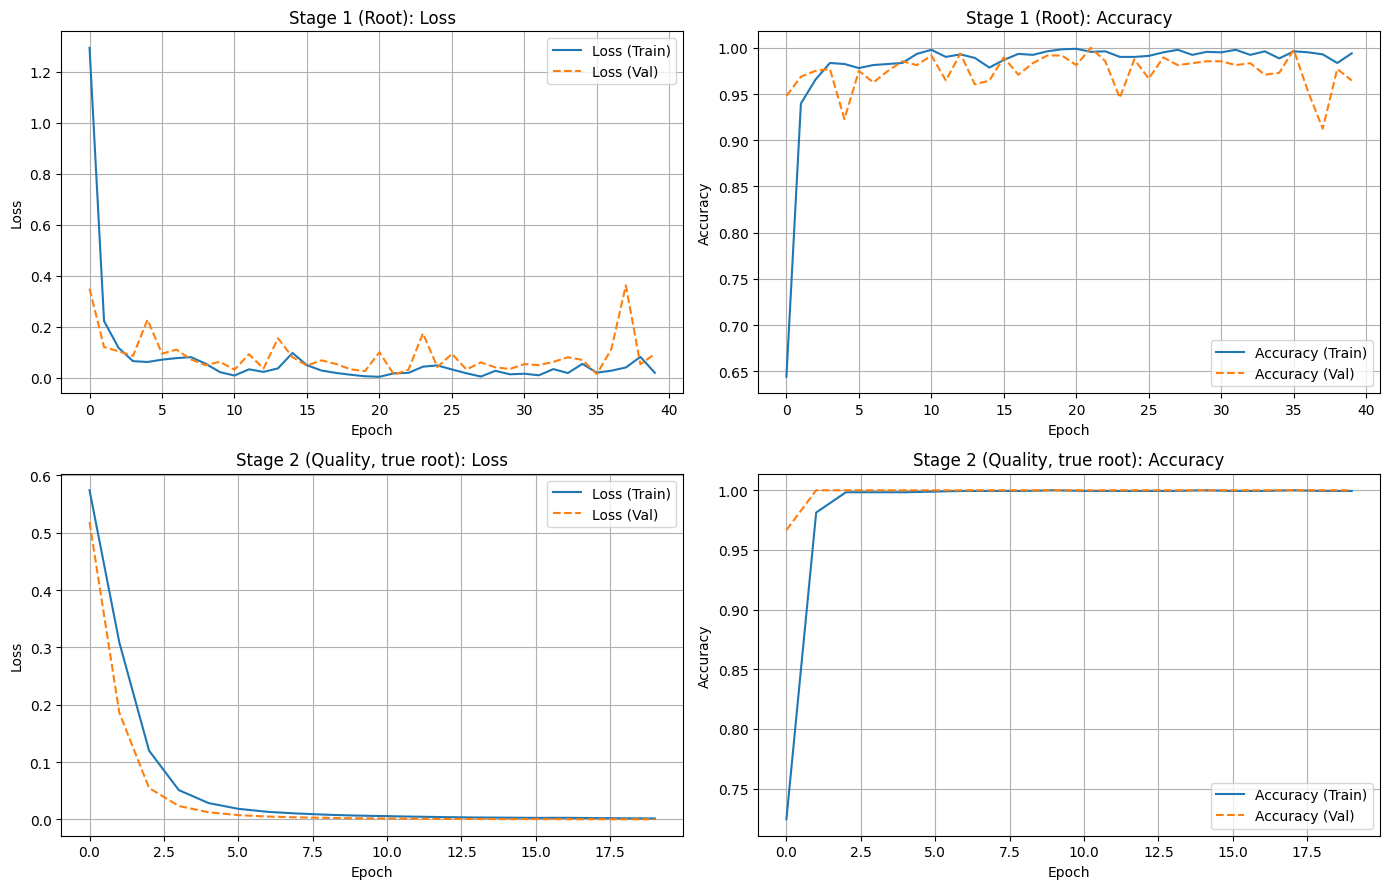

In [ ]:
import matplotlib.pyplot as plt

# Run after both models are trained. Needs root_history and quality_history
# (the return values of root_model.fit(...) and quality_model.fit(...)).
fig, axes = plt.subplots(2, 2, figsize=(14, 9))


def plot_history(history, title, ax_loss, ax_acc):
    h = history.history

    ax_loss.plot(h['loss'], label='Loss (Train)')
    ax_loss.plot(h['val_loss'], label='Loss (Val)', linestyle='--')
    ax_loss.set_title(f'{title}: Loss')
    ax_loss.set_xlabel('Epoch')
    ax_loss.set_ylabel('Loss')
    ax_loss.legend()
    ax_loss.grid(True)

    ax_acc.plot(h['accuracy'], label='Accuracy (Train)')
    ax_acc.plot(h['val_accuracy'], label='Accuracy (Val)', linestyle='--')
    ax_acc.set_title(f'{title}: Accuracy')
    ax_acc.set_xlabel('Epoch')
    ax_acc.set_ylabel('Accuracy')
    ax_acc.legend()
    ax_acc.grid(True)


plot_history(root_history, 'Stage 1 (Root)', axes[0, 0], axes[0, 1])
plot_history(quality_history, 'Stage 2 (Quality, true root)', axes[1, 0], axes[1, 1])

plt.tight_layout()
plt.show()

In [ ]:
# ---------------- Evaluate the full cascade ----------------
root_pred = root_model.predict(xf_test, verbose=0).argmax(axis=1)

q_true_root = (quality_model.predict(root_relative(xp_test, y_root_test), verbose=0).ravel() > 0.5).astype(int)
q_pred_root = (quality_model.predict(root_relative(xp_test, root_pred), verbose=0).ravel() > 0.5).astype(int)

root_ok = root_pred == y_root_test
print(f'\nRoot accuracy (stage 1)                    : {root_ok.mean():.3f}')
print(f'Quality accuracy, given the TRUE root       : {(q_true_root == y_quality_test).mean():.3f}   <- ceiling for stage 2')
print(f'Quality accuracy, given the PREDICTED root  : {(q_pred_root == y_quality_test).mean():.3f}   <- what you get live')
print(f'Whole chord right (root AND quality)        : {(root_ok & (q_pred_root == y_quality_test)).mean():.3f}')
print('Quality confusion with predicted root (rows=true Maj/Min):\n',
      confusion_matrix(y_quality_test, q_pred_root))

root_model.save('chord_root_model.keras')
quality_model.save('chord_quality_model.keras')

# Inference for one window `seg` (24576 samples, mono, 48 kHz):
#   root    = root_model(fft_features(seg)[None]).argmax()
#   rel     = root_relative(pc_features(seg)[None], np.array([root]))
#   quality = 'Minor' if quality_model(rel) > 0.5 else 'Major'


Root accuracy (stage 1)                    : 0.965
Quality accuracy, given the TRUE root       : 1.000   <- ceiling for stage 2
Quality accuracy, given the PREDICTED root  : 0.969   <- what you get live
Whole chord right (root AND quality)        : 0.965
Quality confusion with predicted root (rows=true Maj/Min):
 [[ 96   0]
 [ 15 369]]


In [ ]:
from google.colab import files

files.download("chord_root_model.keras")
files.download("chord_quality_model.keras")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>